# 4) Ligand Composition Analysis

In [ ]:
import os
import sys
from collections import Counter

import numpy as np
import scope
import scope_sco

sys.path.insert(0, os.path.abspath('..'))
from atlas_functions import *

import matplotlib.pyplot as plt

## 1. User Configuration

In [ ]:
data_path     = "/Users/sergivela/Documents/SCOPE/Database_SCO/Data/"                    # Update with your path
analysis_path = "/Users/sergivela/Documents/SCOPE/Database_SCO/Analysis/"                # Update with your path 
env_path      = "/Users/sergivela/Documents/SCOPE/Database_SCO/Data/scope_env_atlas.npy" # Update with your path

save_figures  = True
if save_figures: 
    figures_path = "/Users/sergivela/Documents/SCOPE/Database_SCO/Manuscript/figures/"       # Update with your path
else:
    figures_path = None 

# Normalizes the configured strings and defines the analysis output folder.
data_path     = os.path.abspath(os.path.expanduser(data_path)) + os.sep
env_path      = os.path.abspath(os.path.expanduser(env_path))
analysis_path = os.path.abspath(os.path.expanduser(analysis_path)) + os.sep
outputs_path  = analysis_path + "Outputs/"

# Checks Scope Version
expected_scope_version = "0.9.6"
installed_scope_version = getattr(scope, "__version__", None)
if installed_scope_version != expected_scope_version:
    raise RuntimeError(f"This analysis requires SCOPE {expected_scope_version}; the active environment provides {installed_scope_version!r}.")

# This folders are required, together with the system-dedicated folders inside
required_data_paths = [data_path + "2-Systems/", data_path + "3-Computations/"]
missing_paths       = [path for path in required_data_paths if not os.path.isdir(path)]
if missing_paths:
    raise FileNotFoundError(f"Missing required SCO ATLAS data directories: {missing_paths}")
if not os.path.isfile(env_path):
    raise FileNotFoundError(f"SCOPE environment file not found: {env_path}")
os.makedirs(outputs_path, exist_ok=True)

# Loads Environment
env = scope.load_binary(env_path)

print(f"SCOPE version:      {installed_scope_version}")
print(f"Data directory:     {data_path}")
print(f"SCOPE environment:  {env_path}")
print(f"Analysis outputs:   {outputs_path}")
print(f"Manuscript Figures: {figures_path}")

SCOPE version:      0.9.6
Data directory:     /Users/sergivela/Documents/SCOPE/Database_SCO/Data/
SCOPE environment:  /Users/sergivela/Documents/SCOPE/Database_SCO/Data/scope_env_atlas.npy
Analysis outputs:   /Users/sergivela/Documents/SCOPE/Database_SCO/Analysis/Outputs/
Manuscript Figures: /Users/sergivela/Documents/SCOPE/Database_SCO/Manuscript/figures


In [ ]:
## Additional Paths for this notebook
thermo_csv_path         = outputs_path+'/unique_thermodynamic_data.csv'
bibliography_csv_path   = outputs_path+'/unique_bibliographic_data.csv'

## 2. Load Homoleptic Systems And Data


In [ ]:
systems = []
data    = {}
failed_loads = []

for row in read_csv(thermo_csv_path):
    if row.get('homoleptic') != 'True':  continue

    try:
        system = scope.load_binary(f"{data_path}/{row['path']}")
        system.set_paths_from_environment(env)

        biblio_row = filter_rows(bibliography_csv_path, lambda brow: brow["refcode"] == row['refcode'], first=True)

        data[row['refcode']] = {
            'refcode'           : row['refcode'],
            'path'              : row['path'],
            'dHelec [kJ/mol]'   : as_float(row.get('dHelec[kJ/mol]')),
            'dHvib [kJ/mol]'    : as_float(row.get('dHvib[kJ/mol](T=298K)')),
            'dSvibT [kJ/mol]'   : as_float(row.get('dSvib·T[kJ/mol](T=298K)')),
            'dSelecT [kJ/mol]'  : as_float(row.get('dSelec·T[kJ/mol](T=298K)')),
            'dGtot [kJ/mol]'    : as_float(row.get('dGtot[kJ/mol](T=298K)')),
            'T1/2 [K]'          : as_float(row.get('T12[K]')),
            'homoleptic'        : row.get('homoleptic'),
            'denticity'         : row.get('denticity'),
            'authors'           : biblio_row.get('authors'),
            'last_author'       : get_last_author(biblio_row.get('authors')),
            'year'              : biblio_row.get('year'),
            'journal'           : biblio_row.get('journal'),
        }

        systems.append(system)
    except Exception as exc:
        failed_loads.append((row['refcode'], f"{data_path}/{row['path']}", repr(exc)))

print(f'Loaded homoleptic systems: {len(systems)}')
print(f'Succesful loads: {len(data)}')
print(f'Failed loads: {len(failed_loads)}')
print(f'Top-5 failed cases:', failed_loads[:5])

Loaded homoleptic systems: 299
Succesful loads: 299
Failed loads: 0
Top-5 failed cases: []


## 3. Build Ligand Descriptors

This is the only step that uses `descriptor_type`, `weight_alpha`, `fp_radius`, and `fp_n_bits`. The map-generation function below receives these precomputed descriptor records.


In [ ]:
# Descriptor controls. These are used only in the descriptor-construction cell below.
descriptor_type = 2      # 1 = unweighted, 2 = distance-weighted Morgan descriptor.
fp_alpha        = 0.25
fp_radius       = 2
fp_n_bits       = 1024

descriptor_records, descriptor_failures = collect_ligands_data(systems,descriptor_type,fp_alpha,fp_radius,fp_n_bits)
print(f'Descriptor records: {len(descriptor_records)}')
print(f'Descriptor failures: {len(descriptor_failures)}')
descriptor_failures[:5]

Descriptor records: 299
Descriptor failures: 0


[]

## 4. Generate Interactive Map

The tree map keeps family centers in continuous similarity space, whereas the grid map snaps family centers to sparse bins to improve navigation.


In [ ]:
# sanitize_filename() is imported from atlas_functions.py.

In [ ]:
map_type         = 'grid' # 'tree' or 'grid'
embedding_method = 'mds'  # 'mds' or 'pca'
target_denticities = [1,2,3,6]
properties = ['dHelec', 'T1/2', 'year', 'journal', 'last_author']

for target_denticity in target_denticities:
    for color_property in properties:
        # Tooltip controls. Units are omitted automatically when the value is missing.
        properties_to_show = {
            'Last author': {'key': 'last_author'},
            'Journal': {'key': 'journal'},
            'Year': {'key': 'year', 'digits': 0},
            'dHelec': {'key': 'dHelec', 'unit': 'kJ/mol'},
            'dHvib': {'key': 'dHvib', 'unit': 'kJ/mol'},
            'dSvibT': {'key': 'dSvibT', 'unit': 'kJ/mol'},
            'dGtot': {'key': 'dGtot', 'unit': 'kJ/mol'},
            'T1/2': {'key': 'T1/2', 'unit': 'K'},
        }
    
        common_kwargs = dict(
            descriptor_records=descriptor_records,
            data=data,
            properties_to_show=properties_to_show,
            color_property=color_property,
            target_denticity=target_denticity,
            embedding_method=embedding_method,
            family_min_distance=0.05,
            local_member_min_distance=0.40,
            grid_member_radius=0.40,
            top_n_categories=20,
        )
    
        if map_type == 'tree':
            output_path = os.path.join(figures_path, f'Tree_Map_d{target_denticity}_by_{sanitize_filename(color_property)}')
            map_result  = generate_core_ring_interactive_map(**common_kwargs, grid=False, output_path=output_path) 
        elif map_type == 'grid':
            output_path = os.path.join(figures_path, f'Grid_Map_d{target_denticity}_by_{sanitize_filename(color_property)}')
            map_result  = generate_core_ring_interactive_map(**common_kwargs, grid=True, output_path=output_path) 
        else:
            raise ValueError("map_type must be 'tree' or 'grid'")
    
        print(f"HTML version of Map created in: {map_result['html_path']}")
        print(f"PNG version of Map created in: {map_result['png_path']}")
        print(f"CSV with data stored in: {map_result['csv_path']}")
        print(f"Descriptor failures: {len(descriptor_failures)}")
        print(f"Systems mapped for d={target_denticity}: {len(map_result['map_df'])}")
        print(f"Core-ring families: {len(map_result['family_rows'])}")
        #map_result['map_df'].head()


HTML version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Manuscript/figures/Grid_Map_d1_by_dHelec.html
PNG version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Manuscript/figures/Grid_Map_d1_by_dHelec.png
CSV with data stored in: /Users/sergivela/Documents/SCOPE/Database_SCO/Manuscript/figures/Grid_Map_d1_by_dHelec.csv
Descriptor failures: 0
Systems mapped for d=1: 12
Core-ring families: 4
HTML version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Manuscript/figures/Grid_Map_d1_by_T12.html
PNG version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Manuscript/figures/Grid_Map_d1_by_T12.png
CSV with data stored in: /Users/sergivela/Documents/SCOPE/Database_SCO/Manuscript/figures/Grid_Map_d1_by_T12.csv
Descriptor failures: 0
Systems mapped for d=1: 12
Core-ring families: 4
HTML version of Map created in: /Users/sergivela/Documents/SCOPE/Database_SCO/Manuscript/figures/Grid_Map_d1_by_year.html
PNG version of Map 

## 5. Family-Level $\Delta H_{\mathrm{elec}}$ Statistics and Distributions

For each sufficiently populated ligand family, the main distribution is identified from all systems that passed the project-wide structural filter. The family baseline, $\Delta H_{\mathrm{elec}}^{base}$, is the median of this distribution, while the electronic tunability, $\Delta H_{\mathrm{elec}}^{width}$, is the range spanned by its accepted members.


In [ ]:
minimum_central_members  = 6
minimum_central_fraction = 0.60
central_max_gap           = 15.0  # kJ/mol
outlier_iqr_factor        = 1.5

map_data = {
    denticity: read_csv(os.path.join(figures_path, f'Grid_Map_d{denticity}_by_dHelec.csv'))
    for denticity in [1, 2, 3, 6]
}
family_statistics, family_membership = ligand_family_dhelec_statistics(
    map_data, minimum_central_members, minimum_central_fraction,
    central_max_gap, outlier_iqr_factor,
)

family_statistics_path = os.path.join(outputs_path, 'ligand_family_dHelec_statistics.csv')
family_membership_path = os.path.join(outputs_path, 'ligand_family_dHelec_membership.csv')
statistic_float_columns = {
    'Central Window Min dHelec [kJ/mol]': 2,
    'Central Window Max dHelec [kJ/mol]': 2,
    'dHelec Base [kJ/mol]': 2,
    'dHelec Width [kJ/mol]': 2,
}
write_csv_rows(family_statistics_path, rounded_rows(family_statistics, statistic_float_columns))
write_csv_rows(family_membership_path, rounded_rows(family_membership, {'dHelec [kJ/mol]': 2}))

print(f'Families with a main distribution: {len(family_statistics)}')
print(f'Family statistics saved to: {family_statistics_path}')
print(f'Family membership saved to: {family_membership_path}')
rounded_rows(family_statistics, statistic_float_columns)[:20]


Families with a main distribution: 8
Family statistics saved to: /Users/sergivela/Documents/SCOPE/Database_SCO/Analysis/Outputs/ligand_family_dHelec_statistics.csv
Family membership saved to: /Users/sergivela/Documents/SCOPE/Database_SCO/Analysis/Outputs/ligand_family_dHelec_membership.csv


[{'Denticity': 2,
  'Family': 'F(3,1)',
  'Num Entries': 7,
  'Num Analysed Entries': 7,
  'Num Central Entries': 7,
  'Num Outside Central Distribution': 0,
  'Central Window Min dHelec [kJ/mol]': 52.07,
  'Central Window Max dHelec [kJ/mol]': 57.57,
  'dHelec Base [kJ/mol]': 55.37,
  'dHelec Width [kJ/mol]': 5.51},
 {'Denticity': 2,
  'Family': 'F(4,1)',
  'Num Entries': 11,
  'Num Analysed Entries': 11,
  'Num Central Entries': 11,
  'Num Outside Central Distribution': 0,
  'Central Window Min dHelec [kJ/mol]': -3.5,
  'Central Window Max dHelec [kJ/mol]': 23.54,
  'dHelec Base [kJ/mol]': 21.19,
  'dHelec Width [kJ/mol]': 27.04},
 {'Denticity': 3,
  'Family': 'F(1,5)',
  'Num Entries': 9,
  'Num Analysed Entries': 9,
  'Num Central Entries': 8,
  'Num Outside Central Distribution': 1,
  'Central Window Min dHelec [kJ/mol]': 2.06,
  'Central Window Max dHelec [kJ/mol]': 14.79,
  'dHelec Base [kJ/mol]': 6.75,
  'dHelec Width [kJ/mol]': 12.73},
 {'Denticity': 3,
  'Family': 'F(4,7)',
 

### 5.1 Family-Resolved Distributions

The pale horizontal bands span the electronic tunability, $\Delta H_{\mathrm{elec}}^{width}$, of the accepted main distributions. Orange bands and points show systems outside those distributions. All systems entering this analysis have already passed the project-wide structural filter; no additional structural exclusions are applied here.


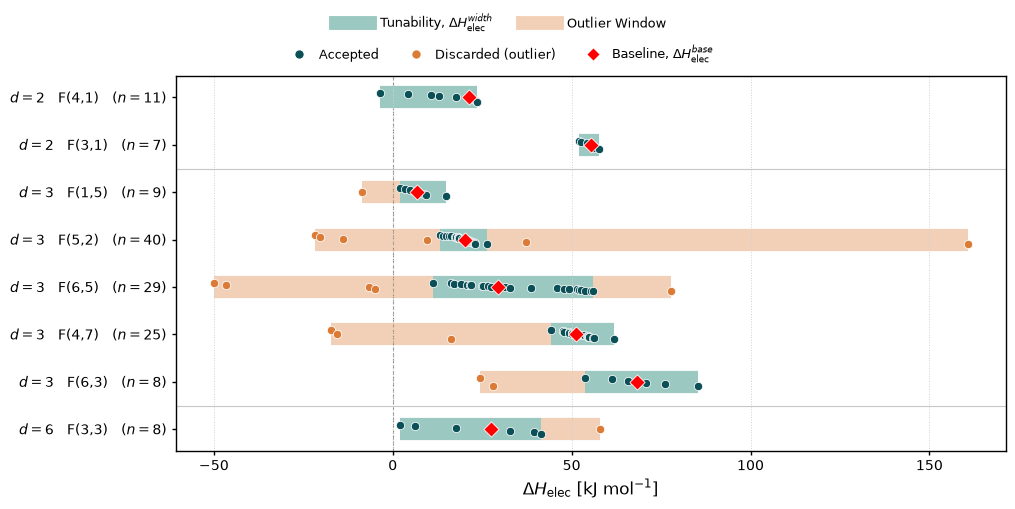

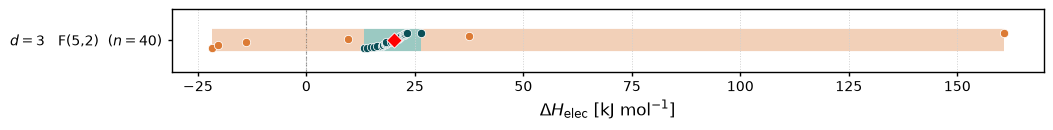

All-family figure saved to: /Users/sergivela/Documents/SCOPE/Database_SCO/Manuscript/figures/dHelec_family_baseline_tunability.png
F(5,2) bpp example saved to: /Users/sergivela/Documents/SCOPE/Database_SCO/Manuscript/figures/dHelec_family_bpp_example.png


In [ ]:
baseline_col    = 'dHelec Base [kJ/mol]'
tunability_col  = 'dHelec Width [kJ/mol]'
central_min_col = 'Central Window Min dHelec [kJ/mol]'
central_max_col = 'Central Window Max dHelec [kJ/mol]'

colors = {
    'central_window': '#9bc9c2',
    'central_point': '#0b4f57',
    'outside': '#dc7b35',
}

plot_rows = sorted(family_statistics, key=lambda row: (int(row['Denticity']), row[baseline_col]))

fig, ax = plt.subplots(figsize=(10.5, 5.2))
fig.subplots_adjust(left=0.19, right=0.98, bottom=0.12, top=0.84)
for y, statistics in enumerate(plot_rows):
    denticity = int(statistics['Denticity'])
    family = statistics['Family']
    members = [
        row for row in map_data[denticity]
        if row['family_id'] == family and as_float(row.get('dHelec [kJ/mol]')) is not None
    ]
    draw_family_distribution(ax, y, members, statistics, colors=colors)

ax.set_yticks(
    range(len(plot_rows)),
    [
        rf'$d={int(row["Denticity"])}$   {row["Family"]}   $(n={int(row["Num Analysed Entries"])})$'
        for row in plot_rows
    ],
)
ax.invert_yaxis()
ax.axvline(0, color='0.55', linestyle='--', linewidth=0.8, zorder=0)

for boundary in [
    i + 0.5 for i in range(len(plot_rows) - 1)
    if plot_rows[i]['Denticity'] != plot_rows[i + 1]['Denticity']
]:
    ax.axhline(boundary, color='0.78', linewidth=0.8, zorder=0)

ax.set_xlabel(r'$\Delta H_{\mathrm{elec}}$ [kJ mol$^{-1}$]', fontsize=12)
ax.tick_params(direction='out', length=3, width=1)
ax.grid(axis='x', linestyle=':', color='0.82', linewidth=0.7, zorder=0)
for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(1.0)
add_family_legends(fig, colors=colors)

all_families_path = os.path.join(figures_path, 'dHelec_family_baseline_tunability.png')
all_families_pdf  = os.path.join(figures_path, 'dHelec_family_baseline_tunability.pdf')
plt.savefig(all_families_path, dpi=400, bbox_inches='tight')
plt.savefig(all_families_pdf, bbox_inches='tight')
plt.show()

# Standalone bpp worked example for the ESI.
example_family = next(row['family_id'] for row in map_data[3] if row['Refcode'] == 'BUTPOY')
example = next(
    row for row in family_statistics
    if int(row['Denticity']) == 3 and row['Family'] == example_family
)
example_members = [
    row for row in map_data[3]
    if row['family_id'] == example_family and as_float(row.get('dHelec [kJ/mol]')) is not None
]

fig, ax = plt.subplots(figsize=(10.5, 2.4))
fig.subplots_adjust(left=0.15, right=0.98, bottom=0.24, top=0.5)
draw_family_distribution(ax, 0, example_members, example, colors=colors)
ax.set_yticks([0], [rf'$d=3$   {example_family}  ($n={int(example["Num Analysed Entries"])}$)'])
ax.set_ylim(-0.36, 0.36)
ax.axvline(0, color='0.55', linestyle='--', linewidth=0.8, zorder=0)
ax.set_xlabel(r'$\Delta H_{\mathrm{elec}}$ [kJ mol$^{-1}$]', fontsize=12)
ax.grid(axis='x', linestyle=':', color='0.82', linewidth=0.7, zorder=0)
ax.tick_params(direction='out', length=3, width=1)
for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(1.0)

example_path = os.path.join(figures_path, 'dHelec_family_bpp_example.png')
example_pdf  = os.path.join(figures_path, 'dHelec_family_bpp_example.pdf')
plt.savefig(example_path, dpi=400, bbox_inches='tight')
plt.savefig(example_pdf, bbox_inches='tight')
plt.show()

print(f'All-family figure saved to: {all_families_path}')
print(f'{example_family} bpp example saved to: {example_path}')
